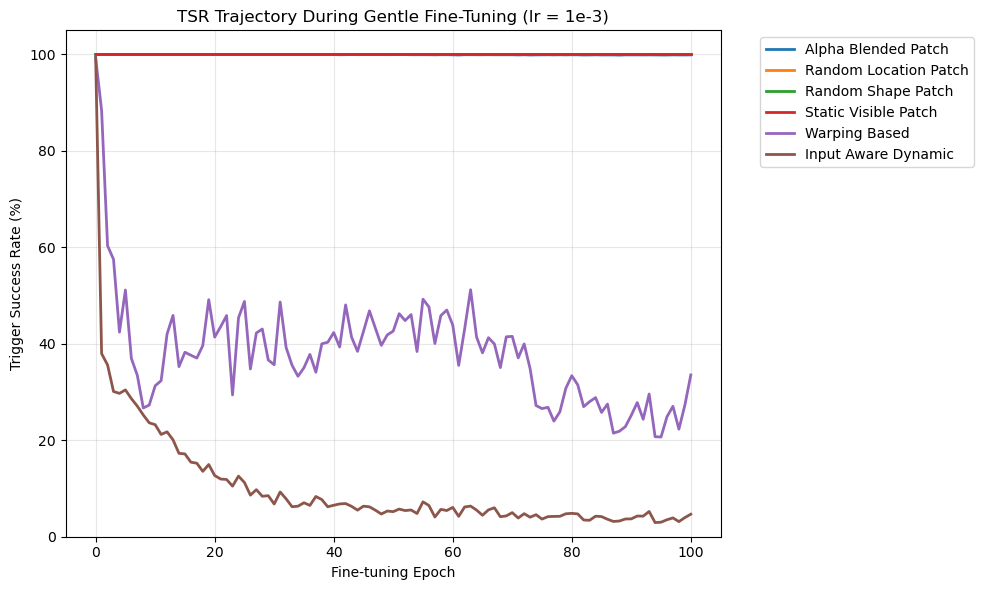

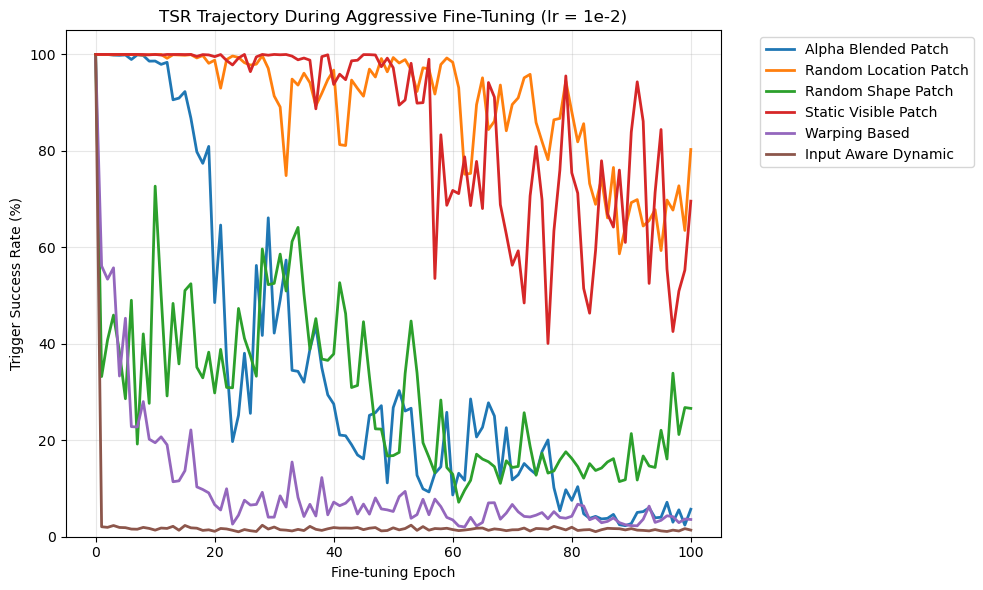

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

gentle_files = {
    "Alpha Blended Patch": Path("patch_trigger/run/finetuning/lr1e-3/ftal_wm_patch_alpha_blended_resnet18_cifar10_lr1e-03.csv"),
    "Random Location Patch": Path("patch_trigger/run/finetuning/lr1e-3/ftal_wm_patch_random_location_resnet18_cifar10_lr1e-03.csv"),
    "Random Shape Patch": Path("patch_trigger/run/finetuning/lr1e-3/ftal_wm_patch_random_shape_resnet18_cifar10_lr1e-03.csv"),
    "Static Visible Patch": Path("patch_trigger/run/finetuning/lr1e-3/ftal_wm_patch_static_visible_resnet18_cifar10_lr1e-03.csv"),
    "Warping Based": Path("warping_based/run/finetuning/lr1e-3/ftal_best_model_lr1e-03.csv"),
    "Input Aware Dynamic": Path("input_aware/run/finetuning/lr1e-3/ftal_best_model_lr1e-03.csv"),
}

aggressive_files = {
    "Alpha Blended Patch": Path("patch_trigger/run/finetuning/lr1e-2/ftal_wm_patch_alpha_blended_resnet18_cifar10_lr1e-02.csv"),
    "Random Location Patch": Path("patch_trigger/run/finetuning/lr1e-2/ftal_wm_patch_random_location_resnet18_cifar10_lr1e-02.csv"),
    "Random Shape Patch": Path("patch_trigger/run/finetuning/lr1e-2/ftal_wm_patch_random_shape_resnet18_cifar10_lr1e-02.csv"),
    "Static Visible Patch": Path("patch_trigger/run/finetuning/lr1e-2/ftal_wm_patch_static_visible_resnet18_cifar10_lr1e-02.csv"),
    "Warping Based": Path("warping_based/run/finetuning/lr1e-2/ftal_best_model_lr1e-02.csv"),
    "Input Aware Dynamic": Path("input_aware/run/finetuning/lr1e-2/ftal_best_model_lr1e-02.csv"),
}

def plot_tsr_curves(file_map, title):
    plt.figure(figsize=(10, 6))

    for label, path in file_map.items():
        df = pd.read_csv(path)

        # Keep only rows with epoch values.
        df = df[pd.to_numeric(df["epoch"], errors="coerce").notna()].copy()
        df["epoch"] = df["epoch"].astype(int)

        plt.plot(
            df["epoch"],
            df["tsr_percent"],
            label=label,
            linewidth=2,
        )

    plt.title(title)
    plt.xlabel("Fine-tuning Epoch")
    plt.ylabel("Trigger Success Rate (%)")
    plt.ylim(0, 105)
    plt.grid(True, alpha=0.3)
    plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

plot_tsr_curves(
    gentle_files,
    "TSR Trajectory During Gentle Fine-Tuning (lr = 1e-3)",
)

plot_tsr_curves(
    aggressive_files,
    "TSR Trajectory During Aggressive Fine-Tuning (lr = 1e-2)",
)

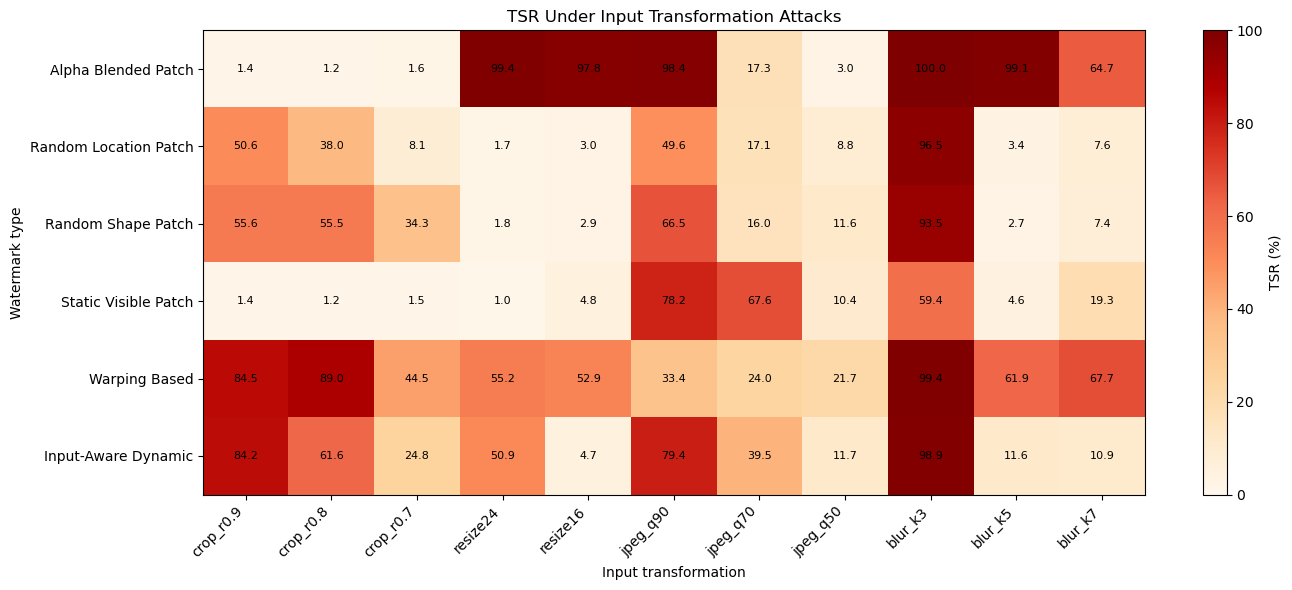

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

data = {
    "Watermark Type": [
        "Alpha Blended Patch",
        "Random Location Patch",
        "Random Shape Patch",
        "Static Visible Patch",
        "Warping Based",
        "Input-Aware Dynamic",
    ],
    "crop_r0.9": [1.40, 50.63, 55.64, 1.37, 84.50, 84.18],
    "crop_r0.8": [1.24, 37.96, 55.48, 1.18, 89.01, 61.61],
    "crop_r0.7": [1.64, 8.13, 34.28, 1.52, 44.54, 24.78],
    "resize24": [99.38, 1.67, 1.84, 1.00, 55.18, 50.88],
    "resize16": [97.77, 3.02, 2.87, 4.76, 52.93, 4.70],
    "jpeg_q90": [98.37, 49.58, 66.47, 78.18, 33.41, 79.41],
    "jpeg_q70": [17.29, 17.09, 15.97, 67.58, 24.04, 39.49],
    "jpeg_q50": [3.00, 8.78, 11.64, 10.42, 21.74, 11.69],
    "blur_k3": [99.98, 96.50, 93.53, 59.36, 99.44, 98.93],
    "blur_k5": [99.11, 3.38, 2.74, 4.63, 61.88, 11.58],
    "blur_k7": [64.70, 7.57, 7.42, 19.34, 67.68, 10.90],
}

df = pd.DataFrame(data)
df = df.set_index("Watermark Type")

plt.figure(figsize=(14, 6))

image = plt.imshow(df.values, aspect="auto", cmap="OrRd", vmin=0, vmax=100)
plt.colorbar(image, label="TSR (%)")

plt.xticks(
    range(len(df.columns)),
    df.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(df.index)),
    df.index
)

plt.title("TSR Under Input Transformation Attacks")
plt.xlabel("Input transformation")
plt.ylabel("Watermark type")

# Add values inside the heatmap cells
for i in range(df.shape[0]):
    for j in range(df.shape[1]):
        plt.text(
            j,
            i,
            f"{df.iloc[i, j]:.1f}",
            ha="center",
            va="center",
            fontsize=8,
        )

plt.tight_layout()
plt.show()